# House Price Prediction Using Machine Learning

## 1. Project Introduction

### Project Overview

The aim of this project is to develop a machine learning model that predicts residential house sale prices based on different property characteristics.

The project uses the Ames Housing dataset from Kaggle, which contains information about residential properties, including their size, quality, location, and other features.

### Project Objectives

- Explore and understand the housing dataset.
- Identify and handle missing values.
- Perform exploratory data analysis.
- Build and train machine learning regression models.
- Evaluate model performance using appropriate metrics.
- Develop an interactive dashboard that allows users to estimate house prices.

### Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Gradio

**Target variable:** `SalePrice`

**Dataset:** [Kaggle – House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data)

## 2. Libraries and Dataset

In this section, we import the required Python libraries and load the Ames Housing dataset for further analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

import joblib

In [1]:
from google.colab import files

uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv


In [3]:
# Load the training dataset
df = pd.read_csv("train.csv")

# Load the Kaggle test dataset
test_df = pd.read_csv("test.csv")

print("Training dataset shape:", df.shape)
print("Test dataset shape:", test_df.shape)

# Display the first five rows
df.head()

Training dataset shape: (1460, 81)
Test dataset shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the dataset, identify patterns, examine relationships between variables, and detect missing values before building the machine learning model.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
print("Average house price:", round(df["SalePrice"].mean(), 2))
print("Minimum house price:", df["SalePrice"].min())
print("Maximum house price:", df["SalePrice"].max())

Average house price: 180921.2
Minimum house price: 34900
Maximum house price: 755000


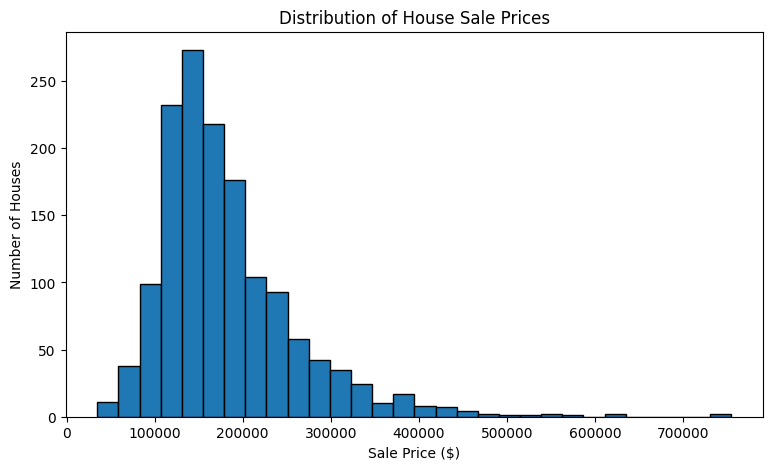

In [7]:
plt.figure(figsize=(9, 5))

plt.hist(df["SalePrice"], bins=30, edgecolor="black")

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

### House Price Distribution

The histogram illustrates the distribution of house sale prices. It helps identify the most common price ranges and shows whether the data contains unusually expensive properties.

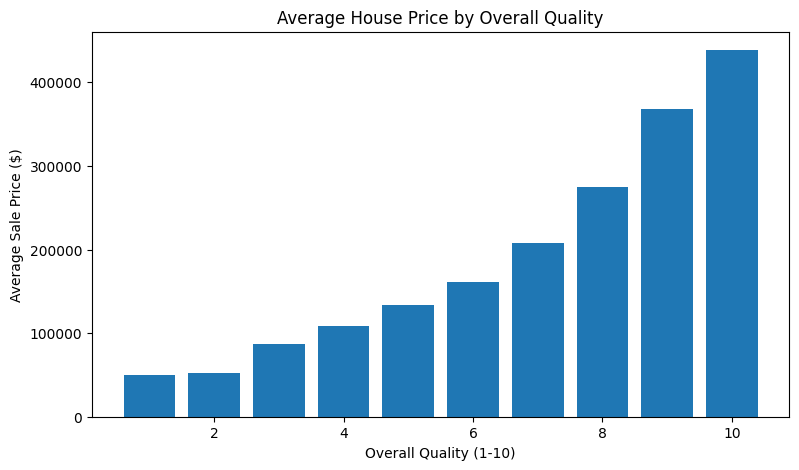

In [8]:
quality_prices = df.groupby("OverallQual")["SalePrice"].mean()

plt.figure(figsize=(9, 5))

plt.bar(quality_prices.index, quality_prices.values)

plt.title("Average House Price by Overall Quality")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("Average Sale Price ($)")

plt.show()

### Relationship Between House Quality and Sale Price

This chart examines how average house sale prices vary with overall quality. It helps identify whether higher-quality houses generally have higher market values.

In [9]:
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values = missing_values[missing_values > 0]

print("Number of columns with missing values:", len(missing_values))
print(missing_values.head(20))

Number of columns with missing values: 19
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


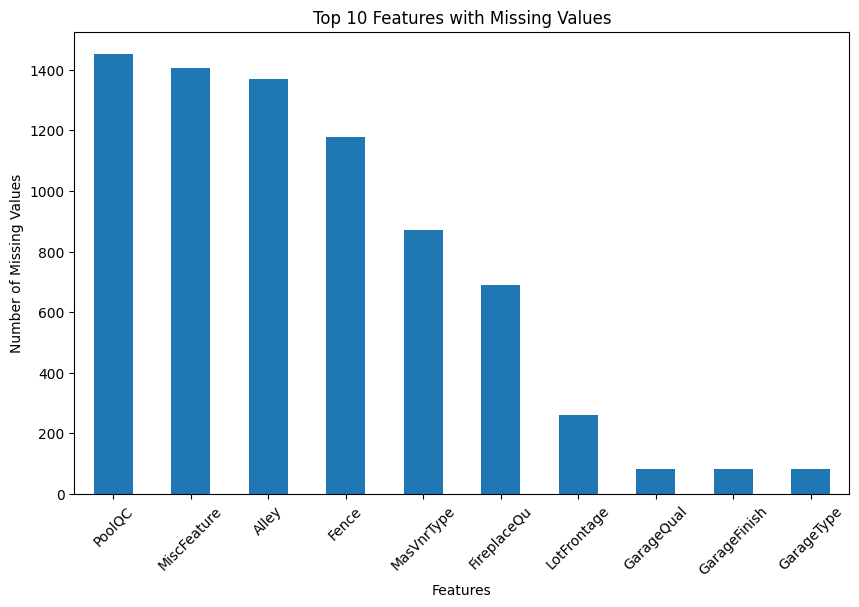

In [10]:
plt.figure(figsize=(10, 6))

missing_values.head(10).plot(kind="bar")

plt.title("Top 10 Features with Missing Values")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.show()

### Missing Values Analysis

The dataset contains missing values in 19 columns. Some missing values indicate the absence of a property feature, such as a swimming pool or alley access. These values will be handled during preprocessing using appropriate imputation techniques.

## 4. Data Preprocessing

In this section, we prepare the dataset for machine learning by separating the target variable, identifying numerical and categorical features, and handling missing values.

In [11]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 80)
Target shape: (1460,)


## 5. Train/Test Split and Feature Identification

The dataset is divided into training and testing sets. The training set is used to train the machine learning model, while the testing set is used to evaluate its performance on unseen data.

The dataset is also divided into numerical and categorical features so that each type can be processed appropriately.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 80)
Testing data: (292, 80)


In [13]:
numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(exclude="number").columns

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 37
Categorical features: 43


In [14]:
# Handle missing numerical values
numeric_transformer = SimpleImputer(strategy="median")

# Handle missing categorical values
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 6. Model Training

In this section, a Random Forest Regressor is used to predict house sale prices.

The model is combined with the preprocessing pipeline to handle missing values and categorical features automatically during training.

In [15]:
# Create the machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## 7. Model Evaluation

The model is evaluated using Mean Absolute Error (MAE) and the R² score.

Five-fold cross-validation is also performed to examine the consistency of model performance.

A scatter plot compares actual house prices with predicted prices to visualize the model's accuracy.

In [16]:
# Predict prices for the test houses
predictions = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))
print("R² Score:", round(r2, 3))

Mean Absolute Error: 17818.64
R² Score: 0.887


In [17]:
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_mae = -cv_scores

print("MAE for each fold:", cv_mae.round(2))
print("Average CV MAE:", round(cv_mae.mean(), 2))

MAE for each fold: [16637.48 20106.93 20369.43 17734.16 16645.25]
Average CV MAE: 18298.65


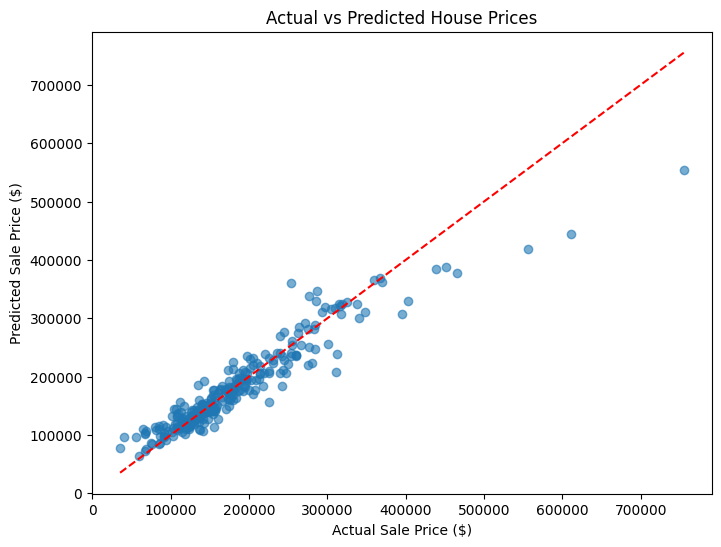

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")

plt.show()

### Model Evaluation Results

The Random Forest model achieved a Mean Absolute Error (MAE) of $17,818.64 and an R² score of 0.887 on the test dataset.

Five-fold cross-validation produced an average MAE of $18,298.65. These results indicate that the model performs reasonably consistently on unseen data.

The actual-versus-predicted scatter plot shows that most predictions are relatively close to the actual sale prices, although some larger errors occur, particularly for more expensive properties.

## 8. Feature Importance

Feature importance analysis is used to identify which house characteristics contribute most to the Random Forest model's predictions.

The most important features are displayed in a chart to help interpret the model's behavior.

In [19]:
import pandas as pd

feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importances = model.named_steps["regressor"].feature_importances_

feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

print(feature_importance.head(15))

num__OverallQual     0.557629
num__GrLivArea       0.122465
num__TotalBsmtSF     0.034790
num__2ndFlrSF        0.033585
num__BsmtFinSF1      0.028835
num__1stFlrSF        0.025500
num__LotArea         0.016575
num__GarageArea      0.015193
num__YearBuilt       0.012749
num__GarageCars      0.011927
num__LotFrontage     0.008030
num__TotRmsAbvGrd    0.006929
num__YearRemodAdd    0.006464
num__OpenPorchSF     0.005771
num__FullBath        0.005742
dtype: float64


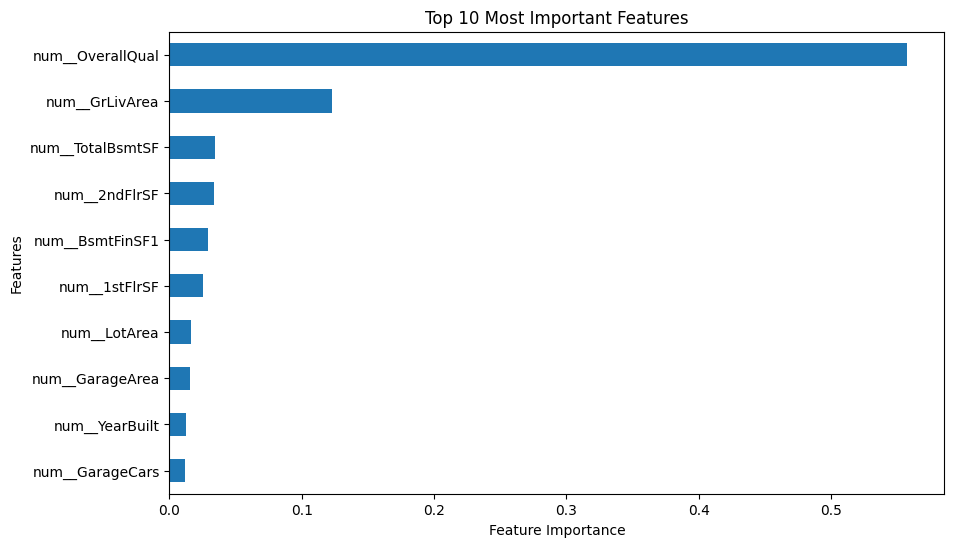

In [20]:
plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Most Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()

### Feature Importance Analysis

The feature importance analysis shows that Overall Quality is the most influential feature in the Random Forest model, with an importance score of approximately 0.558.

GrLivArea (above-ground living area) is the second most important feature, followed by TotalBsmtSF (total basement area).

These results suggest that the model relies heavily on the overall quality and size of a property when estimating its sale price. Feature importance indicates predictive contribution within the model and does not establish causation.

In [21]:
joblib.dump(model, "house_price_model.joblib")

print("Model saved successfully!")

Model saved successfully!


## 9. House Price Prediction Dashboard

This section introduces an interactive dashboard built with Gradio. Users can enter selected house characteristics and receive an estimated sale price from the trained Random Forest model.

The remaining house characteristics are assigned typical values from the training dataset.

In [22]:
import gradio as gr

# Create a typical house using training data
base_house = X_train.median(numeric_only=True).to_frame().T

# Fill categorical features with their most common values
for col in categorical_features:
    base_house[col] = X_train[col].mode()[0]

print("Dashboard data prepared!")

Dashboard data prepared!


In [23]:
def predict_house_price(overall_qual, living_area, basement_area,
                        garage_cars, year_built):

    house = base_house.copy()

    house["OverallQual"] = overall_qual
    house["GrLivArea"] = living_area
    house["TotalBsmtSF"] = basement_area
    house["GarageCars"] = garage_cars
    house["YearBuilt"] = year_built

    prediction = model.predict(house)[0]

    return f"Estimated house price: ${prediction:,.2f}"

In [24]:
demo = gr.Interface(
    fn=predict_house_price,
    inputs=[
        gr.Slider(1, 10, value=5, step=1, label="Overall Quality"),
        gr.Slider(300, 5000, value=1500, step=50, label="Living Area (sq ft)"),
        gr.Slider(0, 3000, value=800, step=50, label="Basement Area (sq ft)"),
        gr.Slider(0, 4, value=2, step=1, label="Garage Capacity (cars)"),
        gr.Slider(1870, 2010, value=2000, step=1, label="Year Built")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="House Price Prediction",
    description="Enter house characteristics to estimate its sale price. Other characteristics use typical training-data values."
)

In [25]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fd00433c2974a28495.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Conclusion

This project developed a machine learning model to predict residential house sale prices using the Ames Housing dataset.

Exploratory data analysis helped identify patterns in house prices, relationships between property characteristics, and missing values.

A Random Forest Regressor was trained using a preprocessing pipeline that handled missing numerical and categorical values.

The final model achieved the following results:

- **Mean Absolute Error (MAE):** $17,818.64

- **R² Score:** 0.887
- **Average Cross-Validation MAE:** $18,298.65

Feature importance analysis showed that Overall Quality and Above-Ground Living Area were among the most influential features used by the model.

Finally, an interactive Gradio dashboard was developed to allow users to enter selected house characteristics and receive estimated sale prices.

### Limitations and Future Improvements

The dashboard uses typical training-data values for house characteristics that users do not enter. Therefore, its predictions are estimates rather than exact market valuations.

Future improvements could include adding more input features, testing additional machine learning algorithms, and improving prediction accuracy.

## 11. Predictions on Kaggle Test Dataset

The Kaggle test dataset contains 1,459 houses without the target variable (`SalePrice`). The trained Random Forest model is used to generate estimated sale prices for these properties.

The same preprocessing steps are automatically applied through the trained machine learning pipeline. The predictions are saved in a CSV file named `submission.csv`, which follows the required Kaggle submission format.

In [26]:
# Generate predictions for the Kaggle test dataset
test_predictions = model.predict(test_df)

# Create Kaggle submission file
submission = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": test_predictions
})

# Save predictions to CSV
submission.to_csv("submission.csv", index=False)

print("Predictions completed successfully!")
print("Submission shape:", submission.shape)
print("\nFirst five predictions:")
display(submission.head())

Predictions completed successfully!
Submission shape: (1459, 2)

First five predictions:


,Id,SalePrice
0,1461,130631.50
1,1462,155748.50
2,1463,177801.50
3,1464,190617.82
4,1465,207639.40


In [27]:
print("Missing values:")
print(submission.isnull().sum())

print("\nNumber of predictions:", len(submission))
print("Submission file saved successfully!")

Missing values:
Id           0
SalePrice    0
dtype: int64

Number of predictions: 1459
Submission file saved successfully!
